<a href="https://colab.research.google.com/github/arshiyanaaz411/flyrank-ml-internship/blob/main/w07_action_playbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-10 — Content Action Playbook

Built on the FlyRank ML Internship starter dataset (`content_refresh_anonymized.csv`, 30,000 rows, 32 clients).
Run order: **Runtime -> Run all**. Every number in the text cells below is filled in by code from the real data.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [1]:
import os, json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import GroupKFold, KFold
from sklearn.metrics import mean_absolute_error
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

# ---- 1. Load the REAL starter dataset (from the public course repo) ----
REPO = "flyrank-ml-internship"
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "--quiet", "https://github.com/arshiyanaaz411/flyrank-ml-internship.git"], check=True)
raw = pd.read_csv(f"{REPO}/data/raw/content_refresh_anonymized.csv")
print("loaded:", raw.shape)

# ctr in the file is a x100 percentage (0.76 means 0.76%). Convert to a fraction.
raw["ctr_frac"] = raw["ctr"] / 100

TARGET, GROUP, ID_COL = "ctr_frac", "client_id", "content_id"
IMPR_COL, AGE_COL, ARCH_COL = "impressions_90d", "content_age_days", "content_type"

os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

df = raw.dropna(subset=[TARGET, GROUP]).reset_index(drop=True)

# avg_position == 0 means "no data", not rank zero
df["avg_position"] = df["avg_position"].replace(0, np.nan)

# Missingness follows content_type, so add has_ flags instead of fillna(0)
for c in ["search_volume", "competition", "cpc", "word_count", "char_count", "avg_position"]:
    df[f"has_{c}"] = df[c].notna().astype(int)

cats = pd.get_dummies(df[["content_type", "main_intent", "competition_level"]].astype(str),
                      prefix=["ct", "intent", "complvl"], dtype=int)
df = pd.concat([df, cats], axis=1)

# Features chosen by hand. EXCLUDED on purpose:
#  clicks_*, sessions_*, engagement/scroll/ai columns -> outcomes (clicks give away ctr)
#  impressions_*, days_with_impressions -> ctr's denominator
#  trend_pct, trend_direction -> label trap (never features)
#  client_id, content_id -> pseudonyms (grouping only)
BASE = ["search_volume", "competition", "cpc", "word_count", "char_count",
        "content_age_days", "days_since_last_update", "avg_position"]
FEATURES = BASE + [c for c in df.columns if c.startswith("has_")] + list(cats.columns)
X, y, g = df[FEATURES], df[TARGET], df[GROUP]
print("rows:", len(df), "| features:", len(FEATURES), "| clients:", g.nunique())

loaded: (30000, 44)
rows: 30000 | features: 26 | clients: 32


## 1. Honest validation: before vs after

**Before:** a random row split. Rows from the same client can sit in both train and test, so the model can pick up
client-specific patterns and the score can look better than it would on new clients.

**After:** grouped split by client (GroupKFold). Every test fold holds only clients the model never saw.
Same model, same features, same metric (MAE, lower is better). Only the split changes.

In [2]:
hgb = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)
base = lambda: DummyRegressor(strategy="median")

def cv_scores(model_fn, splitter, **kw):
    maes, oof = [], np.full(len(df), np.nan)
    for tr, va in splitter.split(X, y, **kw):
        m = model_fn().fit(X.iloc[tr], y.iloc[tr])
        oof[va] = m.predict(X.iloc[va])
        maes.append(mean_absolute_error(y.iloc[va], oof[va]))
    return float(np.mean(maes)), float(np.std(maes)), oof

res = {}
for split_name, splitter, kw in [("random row split (before)", KFold(5, shuffle=True, random_state=42), {}),
                                 ("grouped by client (after)", GroupKFold(5), {"groups": g})]:
    for mname, fn in [("Baseline (median)", base), ("Gradient Boosting", hgb)]:
        mean, std, oof = cv_scores(fn, splitter, **kw)
        res[(mname, split_name)] = (mean, std)
        if split_name.startswith("grouped") and mname == "Gradient Boosting":
            oof_model = oof
        if split_name.startswith("grouped") and mname.startswith("Baseline"):
            oof_base = oof

table = pd.DataFrame({k: {"MAE": v[0], "std across folds": v[1]} for k, v in res.items()}).T
table.index.names = ["model", "split"]
display(table.round(6))

MAE_MODEL = res[("Gradient Boosting", "grouped by client (after)")][0]
MAE_BASE = res[("Baseline (median)", "grouped by client (after)")][0]
MAE_MODEL_RANDOM = res[("Gradient Boosting", "random row split (before)")][0]
rel = (MAE_MODEL - MAE_BASE) / MAE_BASE * 100
beats = MAE_MODEL < MAE_BASE

# Sanity check: with the target shuffled, the model should NOT beat the baseline
rng = np.random.RandomState(0)
y_shuf = pd.Series(rng.permutation(y.values), index=y.index)
sh = []
for tr, va in GroupKFold(5).split(X, y_shuf, groups=g):
    sh.append(mean_absolute_error(y_shuf.iloc[va], hgb().fit(X.iloc[tr], y_shuf.iloc[tr]).predict(X.iloc[va])))
MAE_SHUF = float(np.mean(sh))

verdict = ("The model's MAE is lower than the baseline's under the grouped split, so it carries some signal for new clients."
           if beats else
           "The model's MAE is NOT lower than the baseline's under the grouped split, so these features show no measured gain for new clients. That is a valid result and it shapes how the queue below is framed.")
display(Markdown(
    f"**Measured (grouped by client, 5 folds):** model MAE {MAE_MODEL:.5f} vs baseline MAE {MAE_BASE:.5f} "
    f"({rel:+.1f}% vs baseline). Under a random row split the model's MAE was {MAE_MODEL_RANDOM:.5f}. "
    f"Shuffled-target sanity check MAE: {MAE_SHUF:.5f} (should be about the baseline, not clearly below it). "
    f"{verdict} Directional only: one dataset sample, one time window."))

,,MAE,std across folds
model,split,,
Baseline (median),random row split (before),0.005054,0.000336
Gradient Boosting,random row split (before),0.006373,0.000232
Baseline (median),grouped by client (after),0.005247,0.004376
Gradient Boosting,grouped by client (after),0.006708,0.004405


**Measured (grouped by client, 5 folds):** model MAE 0.00671 vs baseline MAE 0.00525 (+27.9% vs baseline). Under a random row split the model's MAE was 0.00637. Shuffled-target sanity check MAE: 0.00715 (should be about the baseline, not clearly below it). The model's MAE is NOT lower than the baseline's under the grouped split, so these features show no measured gain for new clients. That is a valid result and it shapes how the queue below is framed. Directional only: one dataset sample, one time window.

## 2. Ranked actions + reason codes

**Idea:** the model gives an expected CTR for each item (predicted only from clients it did not train on). An item well below
its expected CTR is a candidate for human review. This is decision-support, not an automatic verdict.

**Noise floor:** a gap smaller than the model's own MAE (grouped CV) is treated as noise.

**Reason codes (rule-based, readable by a person):**
- `R1_BELOW_EXPECTED`: actual CTR is below the model's expectation by more than the noise floor.
- `R2_AGED`: item is older than the refresh threshold.
- `R3_LOW_VOLUME`: too few impressions, CTR is unstable. Goes to a human or is left alone.
- `R4_WITHIN_NOISE`: gap is inside the noise floor. Monitor only.

**Actions:** `REFRESH_CONTENT` (R1 + R2), `REVIEW_TITLE_SNIPPET` (R1 only), `HOLD_LOW_VOLUME` (R3), `MONITOR` (otherwise).

**Priority:** estimated opportunity = impressions x positive gap (extra clicks if the item reached its expected CTR).
Directional estimate, not a forecast.

In [3]:
MIN_IMPR = 100        # below this, CTR is unstable (assumption)
AGE_REFRESH = 180     # days (assumption, check against the decay table below)
NOISE_FLOOR = MAE_MODEL

df["pred_ctr"] = oof_model
df["gap"] = df["pred_ctr"] - df[TARGET]       # positive = below model expectation
impr = df[IMPR_COL].fillna(0)
age = df[AGE_COL]

r1 = df["gap"] > NOISE_FLOOR
r2 = age >= AGE_REFRESH
r3 = impr < MIN_IMPR
r4 = df["gap"].abs() <= NOISE_FLOOR
codes = pd.DataFrame({"R1_BELOW_EXPECTED": r1, "R2_AGED": r2, "R3_LOW_VOLUME": r3, "R4_WITHIN_NOISE": r4})
df["reason_codes"] = codes.apply(lambda r: "|".join([c for c in codes.columns if r[c]]) or "NONE", axis=1)

df["action"] = np.select([r3, r1 & r2, r1], ["HOLD_LOW_VOLUME", "REFRESH_CONTENT", "REVIEW_TITLE_SNIPPET"], default="MONITOR")
df["opportunity"] = impr * df["gap"].clip(lower=0)      # ctr is a fraction, so this is clicks
print(df["action"].value_counts())
if not beats:
    display(Markdown("**Caution:** the model did not beat the baseline under the grouped split (section 1), so the flags below are weak, low-confidence review prompts and should not be treated as findings."))

action
MONITOR                 21379
HOLD_LOW_VOLUME          7994
REFRESH_CONTENT           355
REVIEW_TITLE_SNIPPET      272
Name: count, dtype: int64


**Caution:** the model did not beat the baseline under the grouped split (section 1), so the flags below are weak, low-confidence review prompts and should not be treated as findings.

## 3. Archetypes -> action mapping

Archetype here = `content_type` (an existing column in the data). The table shows how each type looks and which
actions the rules produced. The suggested default play is a starting point for a human, not a rule.

In [4]:
df["archetype"] = df[ARCH_COL].astype(str)
prof = df.groupby("archetype").agg(items=("archetype", "size"),
                                   median_age_days=(AGE_COL, "median"),
                                   median_impressions=(IMPR_COL, "median"),
                                   median_ctr_pct=("ctr", "median"),
                                   median_gap_pct_pts=("gap", lambda s: s.median() * 100)).round(3)
mix = pd.crosstab(df["archetype"], df["action"])
display(prof.join(mix))

,items,median_age_days,median_impressions,median_ctr_pct,median_gap_pct_pts,HOLD_LOW_VOLUME,MONITOR,REFRESH_CONTENT,REVIEW_TITLE_SNIPPET
archetype,,,,,,,,,
comparison article,697,151.0,107.0,0.00,0.581,331,265,1,100
feedly article,2096,291.0,4.0,0.00,0.320,1744,229,72,51
keyword article,27207,236.0,955.0,0.09,0.222,5919,20885,282,121


## 4. Decay / refresh insight

Median CTR by content age bucket (observed association only; age is mixed up with publish cohort, topic and season).

,median_ctr_pct,items
age_bucket,,
"(89.999, 118.0]",0.12,5157
"(118.0, 148.0]",0.08,5299
"(148.0, 236.0]",0.07,5190
"(236.0, 311.0]",0.03,4363
"(311.0, 438.0]",0.06,5170
"(438.0, 564.0]",0.07,4821


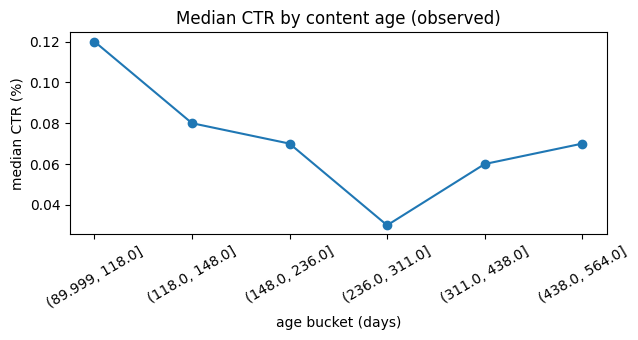

**Observed:** median CTR in the oldest bucket is 0.070% vs 0.120% in the newest bucket (lower for older content). This is an association, not proof that age causes lower CTR.

In [5]:
d = df[[AGE_COL, "ctr"]].dropna()
d["age_bucket"] = pd.qcut(d[AGE_COL], 6, duplicates="drop")
dec = d.groupby("age_bucket", observed=True)["ctr"].agg(median_ctr_pct="median", items="count")
display(dec.round(4))
ax = dec["median_ctr_pct"].plot(marker="o", figsize=(6.5, 3.5))
ax.set_title("Median CTR by content age (observed)")
ax.set_ylabel("median CTR (%)"); ax.set_xlabel("age bucket (days)")
plt.xticks(rotation=30); plt.tight_layout()
plt.savefig("work/figures/decay_by_age.png", dpi=150); plt.show()

first, last = dec["median_ctr_pct"].iloc[0], dec["median_ctr_pct"].iloc[-1]
trend = "lower" if last < first else "higher"
display(Markdown(f"**Observed:** median CTR in the oldest bucket is {last:.3f}% vs {first:.3f}% in the newest bucket ({trend} for older content). "
                 "This is an association, not proof that age causes lower CTR."))

## 5. Intended use and limits

**Intended use:** a ranked review queue that helps an editor decide which items to look at first. Decision-support for planning refresh work.

**Limits**
- One dataset sample and one time window (trailing 90 days). Other periods or other kinds of clients are not tested.
- The gap means "below model expectation", not "bad content". Quality, intent shifts and seasonality are not in the features.
- Opportunity numbers are directional estimates that assume the item could reach its expected CTR.
- Feature use by the model is not cause.
- Non-production: this notebook produces a plan and a queue, not a deployed system.

## 6. Human review + the no-go list

**Human review rules**
- A person reads every item in the top queue before any change is made.
- Every `HOLD_LOW_VOLUME` item is reviewed by a person or left alone.
- The reviewer sees reason codes and the gap, and may override the action with a written reason.
- Spot-check a sample of `MONITOR` items to catch misses.

**Do NOT automate**
- Publishing, rewriting or deleting content from the queue without human approval.
- Pruning pages based on a CTR gap alone.
- Client-facing promises such as "this refresh will lift CTR by X".
- Very low-volume items, brand-new items with no history, or clients not represented in the sample.
- Using the queue to rank or judge people or teams.
- Reading feature importance as a cause.
- Using the queue after a drift or retrain trigger fires, until it is re-validated.

## 7. Cost / value thinking

Effort hours below are placeholders (assumptions, not measurements). The ratio is a way to order work, not an ROI claim.

In [6]:
EFFORT_HRS = {"REFRESH_CONTENT": 3.0, "REVIEW_TITLE_SNIPPET": 0.5, "HOLD_LOW_VOLUME": 0.25, "MONITOR": 0.0}
cv = (df.groupby("action").agg(items=("action", "size"), est_extra_clicks=("opportunity", "sum"))
        .assign(effort_hrs=lambda t: t.index.map(EFFORT_HRS) * t["items"]))
cv["est_clicks_per_hour"] = (cv["est_extra_clicks"] / cv["effort_hrs"]).replace([np.inf], np.nan)
display(cv.round(2))

,items,est_extra_clicks,effort_hrs,est_clicks_per_hour
action,,,,
HOLD_LOW_VOLUME,7994,760.69,1998.5,0.38
MONITOR,21379,229653.35,0.0,NaN
REFRESH_CONTENT,355,25676.44,1065.0,24.11
REVIEW_TITLE_SNIPPET,272,12570.31,136.0,92.43


## 8. Monitoring / retrain triggers

When a new batch arrives:
- **Input drift:** PSI per top feature vs the training sample. Above 0.25 means look closely.
- **Error check:** MAE on new data with known outcomes vs the grouped-CV MAE above. More than 20% worse means pause the queue.
- **Baseline check:** if the model stops beating the baseline on new data, stop using it.
- **Queue sanity:** if the share of flagged items moves sharply (about 2x), investigate first.

**Retrain triggers:** any check above fires, a new client segment is added, CTR measurement changes, or a regular schedule (for example quarterly, an assumption). Re-run grouped validation after retraining.

In [7]:
def psi(a, b, bins=10):
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3: return np.nan
    pa = np.histogram(a, bins=edges)[0] / len(a)
    pb = np.histogram(b, bins=edges)[0] / len(b)
    pa, pb = np.clip(pa, 1e-4, None), np.clip(pb, 1e-4, None)
    return float(np.sum((pb - pa) * np.log(pb / pa)))

# Sanity check of the function: two random halves of the clients
ids = np.array(g.unique()); rng = np.random.RandomState(1); rng.shuffle(ids)
mask = g.isin(set(ids[: len(ids) // 2]))
chk = ["content_age_days", "word_count", "search_volume", "cpc", "days_since_last_update"]
print({f: round(psi(df.loc[mask, f], df.loc[~mask, f]), 3) for f in chk})

TRIGGERS = {"psi_look_closely": 0.25, "mae_worse_than_cv_pct": 20, "must_beat_baseline": True,
            "flag_share_change_factor": 2.0, "scheduled_retrain": "quarterly (assumption)"}

{'content_age_days': 0.223, 'word_count': 0.208, 'search_volume': 0.208, 'cpc': 0.117, 'days_since_last_update': 0.224}


## 9. Exports for the paper

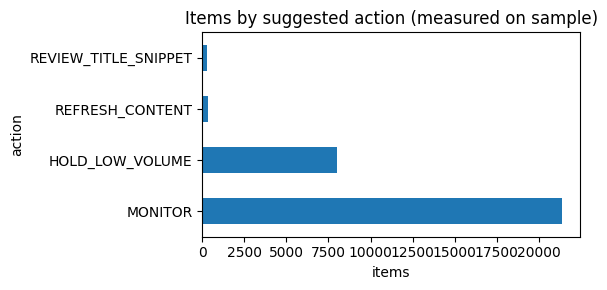

,priority_rank,priority_tier,item_id,client_code,archetype,action,reason_codes,actual_ctr_pct,expected_ctr_pct,gap_pct_pts,est_extra_clicks
0,1,P1,content_44e481c8f55b,c_40970,keyword article,REVIEW_TITLE_SNIPPET,R1_BELOW_EXPECTED,0.65,1.7752,1.1252,3518.40
1,2,P1,content_db5989a78dd3,c_282952,keyword article,REFRESH_CONTENT,R1_BELOW_EXPECTED|R2_AGED,0.21,1.1077,0.8977,3098.03
2,3,P1,content_8f65a4dbfd0e,c_40970,keyword article,REFRESH_CONTENT,R1_BELOW_EXPECTED|R2_AGED,0.05,11.9540,11.9040,1172.30
3,4,P1,content_989e93d58ab9,c_282952,keyword article,REFRESH_CONTENT,R1_BELOW_EXPECTED|R2_AGED,0.29,2.2683,1.9783,1006.33
4,5,P1,content_140e1efff17e,c_40970,keyword article,REFRESH_CONTENT,R1_BELOW_EXPECTED|R2_AGED,0.52,2.6575,2.1375,949.84
5,6,P1,content_629841fd8f2f,c_118191,keyword article,REVIEW_TITLE_SNIPPET,R1_BELOW_EXPECTED,0.09,2.6288,2.5388,769.41
6,7,P1,content_ca17a024f90c,c_282952,keyword article,REFRESH_CONTENT,R1_BELOW_EXPECTED|R2_AGED,0.01,1.8094,1.7994,698.43
7,8,P1,content_9351f948bf45,c_40970,keyword article,REFRESH_CONTENT,R1_BELOW_EXPECTED|R2_AGED,0.88,2.1153,1.2353,632.89
8,9,P1,content_d02df0d34dd5,c_282952,keyword article,REFRESH_CONTENT,R1_BELOW_EXPECTED|R2_AGED,0.12,1.5957,1.4757,577.91
9,10,P1,content_110a32997057,c_40970,keyword article,REFRESH_CONTENT,R1_BELOW_EXPECTED|R2_AGED,0.74,2.6575,1.9175,569.82


Exported: work/outputs/action_queue.csv, work/outputs/w07_metrics.json, work/figures/*.png


In [8]:
df["client_code"] = "c_" + (pd.util.hash_pandas_object(df[GROUP].astype(str), index=False) % 10**6).astype(str)
df["item_id"] = df[ID_COL].astype(str)

actionable = df[df["action"].isin(["REFRESH_CONTENT", "REVIEW_TITLE_SNIPPET"])].copy()
actionable = actionable.sort_values("opportunity", ascending=False).reset_index(drop=True)
actionable["priority_rank"] = actionable.index + 1
actionable["priority_tier"] = pd.qcut(actionable["priority_rank"], 3, labels=["P1", "P2", "P3"]) if len(actionable) >= 3 else "P1"

queue = actionable[["priority_rank", "priority_tier", "item_id", "client_code", "archetype", "action", "reason_codes",
                    "ctr", "pred_ctr", "gap", "opportunity"]].copy()
queue["ctr"] = queue["ctr"].round(4)                    # actual CTR, in percent
queue["pred_ctr"] = (queue["pred_ctr"] * 100).round(4)  # expected CTR, in percent
queue["gap"] = (queue["gap"] * 100).round(4)            # gap, in percentage points
queue["opportunity"] = queue["opportunity"].round(2)    # estimated extra clicks
queue = queue.rename(columns={"ctr": "actual_ctr_pct", "pred_ctr": "expected_ctr_pct", "gap": "gap_pct_pts",
                              "opportunity": "est_extra_clicks"})
queue.to_csv("work/outputs/action_queue.csv", index=False)   # stays out of git by design

metrics = {
    "n_rows": int(len(df)), "n_clients": int(g.nunique()),
    "validation": "GroupKFold(5) by client, out-of-fold predictions",
    "target": "ctr as a fraction (file value / 100)",
    "mae_model_grouped": round(MAE_MODEL, 6), "mae_baseline_grouped": round(MAE_BASE, 6),
    "mae_model_random_split": round(MAE_MODEL_RANDOM, 6),
    "mae_model_shuffled_target": round(MAE_SHUF, 6),
    "model_beats_baseline_grouped": bool(beats),
    "noise_floor": round(NOISE_FLOOR, 6),
    "thresholds": {"min_impr": MIN_IMPR, "age_refresh_days": AGE_REFRESH},
    "action_counts": {k: int(v) for k, v in df["action"].value_counts().items()},
    "queue_length": int(len(queue)),
    "monitoring_triggers": TRIGGERS,
}
with open("work/outputs/w07_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

ax = df["action"].value_counts().plot.barh(figsize=(6, 3))
ax.set_title("Items by suggested action (measured on sample)"); ax.set_xlabel("items")
plt.tight_layout(); plt.savefig("work/figures/action_mix.png", dpi=150); plt.show()

display(queue.head(10))
print("Exported: work/outputs/action_queue.csv, work/outputs/w07_metrics.json, work/figures/*.png")

## Self-check

- [ ] Every section is filled, text and code
- [ ] Runtime -> Run all finishes with no errors
- [ ] No client names, URLs or private queries anywhere
- [ ] Claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to the repo under `work/notebooks/`, then repo URL submitted on the card